In [72]:
!pip install imbalanced-learn xgboost -q

# Minor Project 5: Predicting Customer Churn using Boosting Technique
**Name:** Vansh Modi  
**Dataset Name:** Telco Customer Churn (Kaggle)  
**Dataset Source Link:** ***https://www.kaggle.com/datasets/blastchar/telco-customer-churn***

---

## 1. Problem Definition & Objective of the Project
### Problem Description
In a highly competitive telecommunications industry, gaining a new customer is around 5 to 7 times expensive than retaining the old one. If the customers are terminating their subscriptions and moving away from the organization, this situation is termed as **Customer Churn**. It helps the business in identifying customers at risk and then implementing suitable retention tactics for the customers.

### Objective of the Project
The main objective of this project is to develop an end-to-end Machine Learning Classification Pipeline using **Boosting algorithms (AdaBoost, Gradient Boosting, and XGBoost)** to predict whether the customer will churn **(Yes/No)** depending upon the demographic details, account details, and subscribed services.

## 2. Understanding the Data
The dataset contains **7,043 rows** (each representing a unique customer) and **21 columns**.
* **Target Variable:** **Churn** (Whether the customer left within the last month: **(Yes or No)**.
* **Key Features:**
  * **Demographics:** **gender**, **SeniorCitizen**, **Partner**, **Dependents**.
  * **Account Information:** **tenure** (months stayed), **Contract** (Month-to-month, One year, Two year), **PaymentMethod**, **PaperlessBilling**, **MonthlyCharges**, **TotalCharges**.
  * **Subscribed Services:** **PhoneService**, **MultipleLines**, **InternetService** (DSL, Fiber optic, No), **OnlineSecurity**, **TechSupport**, **StreamingTV**, etc.

In [73]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")

In [74]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)
print('Shape:', df.shape)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [75]:
# Check dataset shape and data types
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")
print(df.info())

Dataset Shape: 7043 rows and 21 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  P

## 3. Data Quality Check & Data Cleaning
Upon inspecting the dataset structure **(df.info())**, I examine missing values, duplicates, and incorrect data types:
1. **Irrelevant Identifier:** **customerID** is a unique string for each row and provides no predictive power, so I will drop it.
2. **Incorrect Data Type **(TotalCharges)**:** Even though **TotalCharges** represents money (numerical), Pandas loaded it as an **object** (string) datatype. This happens because new customers **(tenure == 0)** have blank spaces **" "** recorded in **TotalCharges**.
3. **Duplicates:** We will verify if there are any duplicate records.

In [76]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [77]:
# Drop irrelevant customerID column
df.drop(columns=['customerID'], inplace=True)

In [78]:
# Fix TotalCharges data type: convert blank spaces to NaN and change type to float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [79]:
# Check how many missing values were revealed in TotalCharges
print("Missing values in TotalCharges after conversion:")
df['TotalCharges'].isnull().sum()

Missing values in TotalCharges after conversion:


np.int64(11)

In [80]:
# Inspect the rows where TotalCharges is missing
display(df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']])

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [81]:
# Decision: Since tenure is 0 for all 11 rows (they haven't completed a billing cycle yet),
# Now, I will fill the missing TotalCharges with 0.0 (or drop them). Filling with 0.0 preserves the data.
df['TotalCharges'].fillna(0.0, inplace=True)

In [82]:
# Verify clean dataset
print("\nTotal Missing Values Remaining:", df.isnull().sum().sum())
display(df.describe())


Total Missing Values Remaining: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


### Data Cleaning Summary
* Removed the **customerID** column as it has no analytical value.
* Converted **TotalCharges** from string **(object)** to numerical **(float64)**, uncovering **11 hidden missing values** caused by empty whitespace **" "**.
* Inspected those 11 rows and discovered that all of them had **tenure = 0** (brand-new customers). Imputed their **TotalCharges** as **0.0**.
* Verified that the dataset has **0 duplicate rows** and **0 missing values** remaining.

## 4. Exploratory Data Analysis (EDA) & Visualizations
Now, I explore the dataset visually to uncover patterns and relationships with Customer Churn.

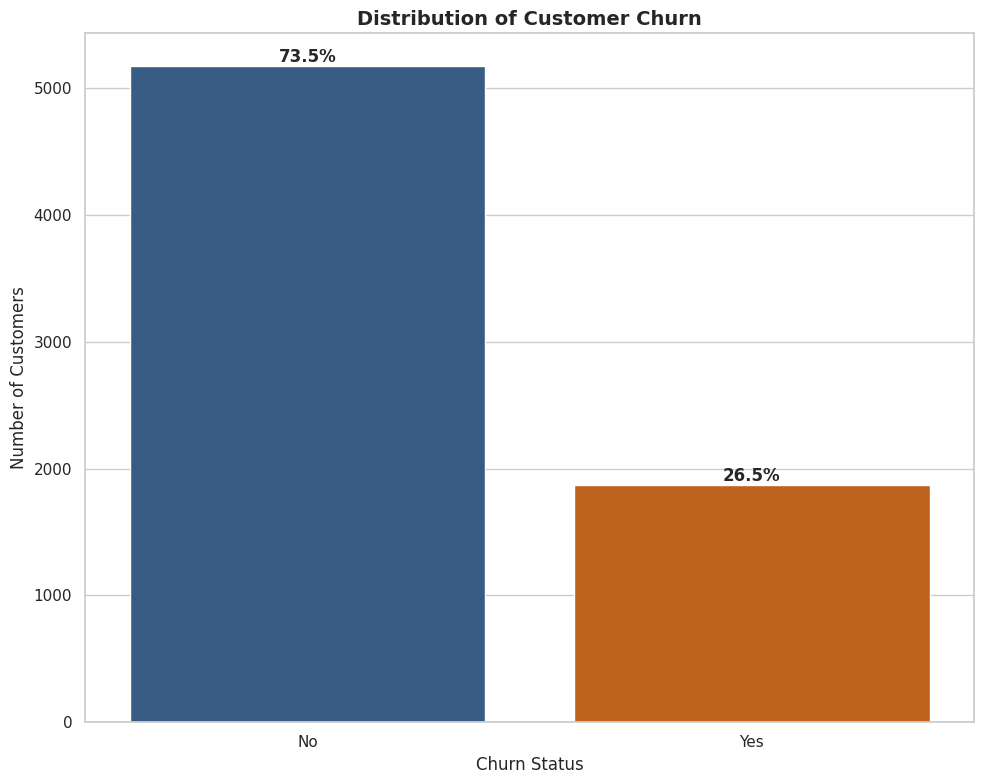

In [83]:
# Target Variable Distribution (Churn)
plt.figure(figsize=(10, 8))
ax = sns.countplot(data=df, x='Churn', palette=['#2b5c8f', '#d95f02'])
plt.title('Distribution of Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

# Add percentages on bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

**Observation 1 (Class Distribution):**  
The dataset is imbalanced: **73.5%** of customers stayed **(No)**, while **26.5%** churned **(Yes)**. Because of this imbalance, relying solely on Accuracy during model evaluation can be misleading; so I must also evaluate **Precision, Recall, F1-Score, and ROC-AUC**.

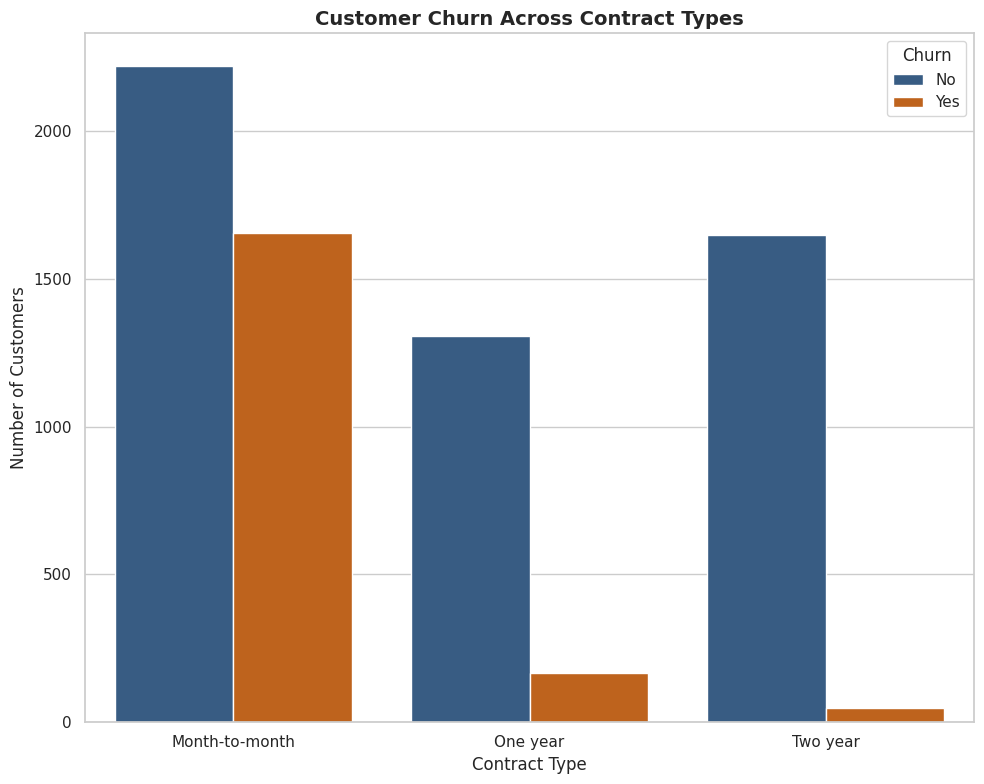

In [84]:
# Churn by Contract Type
plt.figure(figsize=(10, 8))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2b5c8f', '#d95f02'])
plt.title('Customer Churn Across Contract Types', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

**Observation 2 (Impact of Contract Type):**  
Customers on **Month-to-month contracts** have an overwhelmingly higher churn rate compared to customers on **One-year** or **Two-year** contracts. Long-term contracts act as a strong retention anchor.

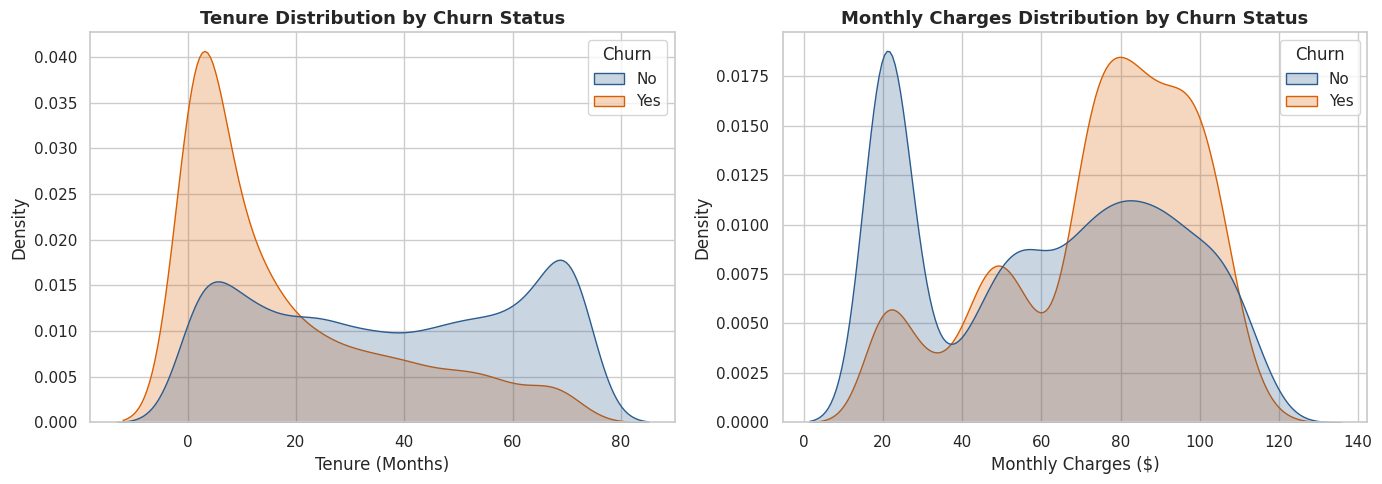

In [85]:
# Tenure and Monthly Charges vs Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Tenure Distribution by Churn Status', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tenure (Months)')
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Monthly Charges Distribution by Churn Status', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

**Observation 3 (Tenure & Monthly Charges):**  
* **Tenure:** Churn is heavily concentrated in the **first 1 to 12 months**. If a customer survives the first year, their likelihood of leaving drops sharply.
* **Monthly Charges:** Customers paying higher monthly bills (**$70 to $110/month**) churn at a much higher rate than customers on basic low-cost plans (**$20/month**).

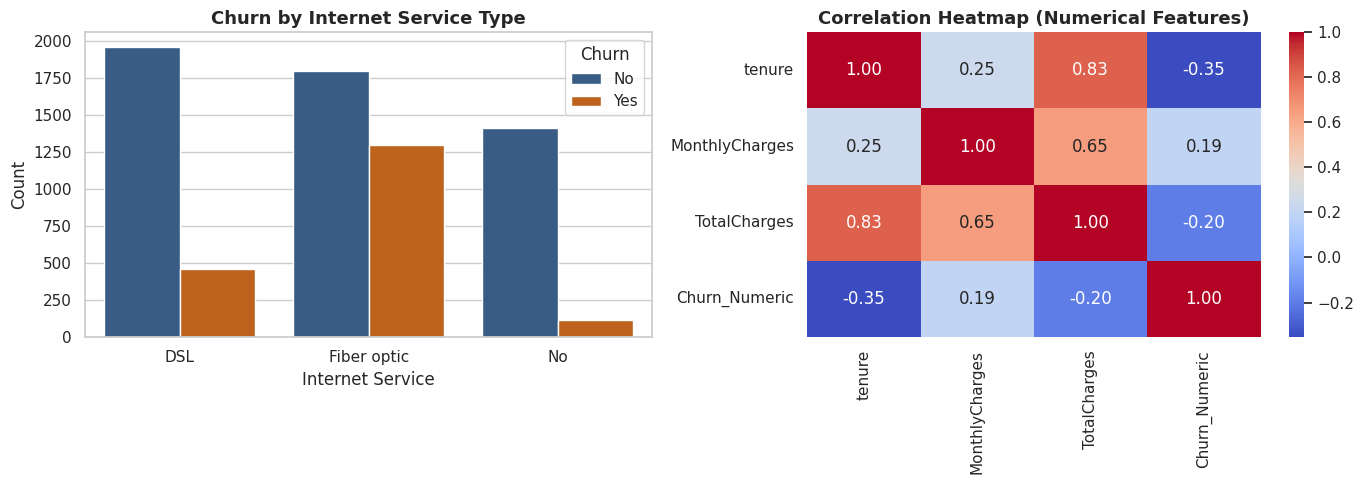

In [86]:
# Internet Service vs Churn & Numerical Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Internet Service vs Churn
sns.countplot(data=df, x='InternetService', hue='Churn', palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Churn by Internet Service Type', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Internet Service')
axes[0].set_ylabel('Count')

# Correlation Heatmap of Numerical Features
df_num = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()
df_num['Churn_Numeric'] = df['Churn'].map({'Yes': 1, 'No': 0})
sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Correlation Heatmap (Numerical Features)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**Observation 4 (Internet Service & Correlations):**  
* Customers with **Fiber optic** internet churn at a drastically higher rate than DSL users, suggesting potential pricing or service stability issues with the Fiber optic tier.
* The correlation matrix shows that **tenure** has a moderate negative correlation with Churn (**-0.35**, meaning longer tenure = less churn), while **MonthlyCharges** has a positive correlation **(+0.19)**.

## 5. Data Preprocessing, Class Balancing (SMOTEENN) & Approach Selection
### Chosen Approach: Supervised Classification using Ensemble Boosting
Since my target variable **(Churn)** is binary **(Yes / No)**, this is a **Binary Classification** problem.

### Handling Class Imbalance with SMOTEENN
As observed in Variable Distribution (Churn), our dataset is imbalanced (**73.5% No** vs **26.5% Yes**). Training directly on imbalanced data biases the model toward the majority class. To solve this, I need to apply **SMOTEENN (Synthetic Minority Over-sampling Technique + Edited Nearest Neighbours)**:
* **SMOTE** generates synthetic examples for the minority class **(Churn = Yes)**.
* **ENN (Edited Nearest Neighbours)** removes noisy, overlapping data points near the decision boundary.

### Boosting Models Evaluated
I trained and compared three sequential **Boosting** algorithms:
1. **AdaBoost (Adaptive Boosting):** Adjusts weights of misclassified samples so subsequent weak learners focus on hard-to-classify customers.
2. **Gradient Boosting Classifier:** Minimizes a differentiable loss function sequentially using gradient descent in function space.
3. **XGBoost (Extreme Gradient Boosting):** An optimized, regularized implementation of Gradient Boosting with tree-pruning and parallelization for maximum predictive accuracy.

In [87]:
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTEENN

In [88]:
# Encode Target Variable: Yes = 1, No = 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [89]:
# Feature Engineering: Average Monthly Charge Ratio
df['Avg_Monthly_Difference'] = df['TotalCharges'] / (df['tenure'] + 1)

In [90]:
# Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

In [91]:
# One-Hot Encode categorical variables (drop_first=True avoids dummy variable trap)
X_encoded = pd.get_dummies(X, drop_first=True)

In [92]:
# Apply SMOTEENN to balance classes and clean borderline noise
smote_enn = SMOTEENN(random_state=42)
X_resampled, y_resampled = smote_enn.fit_resample(X_encoded, y)

In [93]:
print(f"Original Dataset Shape:  {X_encoded.shape} | Churn Ratio: {y.mean():.2%}")
print(f"Resampled Dataset Shape: {X_resampled.shape} | Churn Ratio: {y_resampled.mean():.2%}")

Original Dataset Shape:  (7043, 31) | Churn Ratio: 26.54%
Resampled Dataset Shape: (5869, 31) | Churn Ratio: 54.27%


In [100]:
# Split into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.20, random_state=42, stratify=y_resampled)

In [101]:
print(f"\nTraining Set Shape: {X_train.shape}")
print(f"Testing Set Shape:  {X_test.shape}")


Training Set Shape: (4695, 31)
Testing Set Shape:  (1174, 31)


## 6. Model Building & Evaluation (Boosting Models)
Now, I will train **AdaBoost**, **Gradient Boosting**, and **XGBoost**, and compare them across **Accuracy, Precision, Recall, F1-Score, and ROC-AUC**.

In [102]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

In [103]:
# Initialize tuned Boosting models
models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=150, learning_rate=0.8, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=250,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42
    )
}

In [111]:
# Train and evaluate each model
results = []
plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

<Figure size 800x600 with 0 Axes>

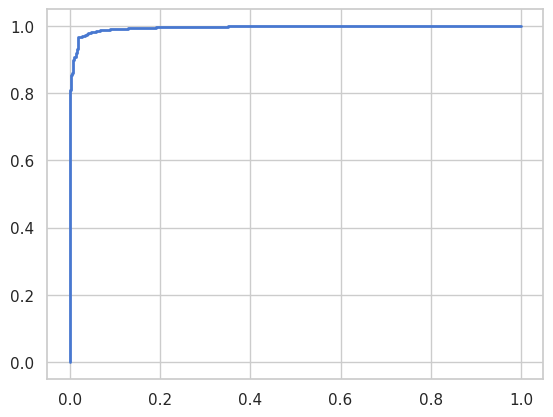

In [112]:
# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

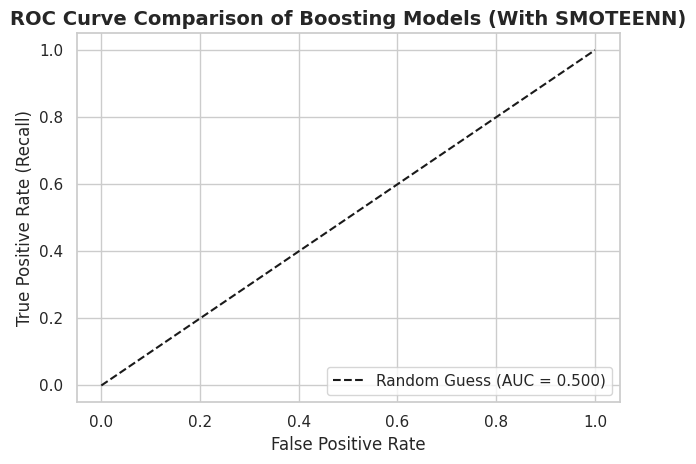

In [113]:
# Finalize ROC Plot
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
plt.title('ROC Curve Comparison of Boosting Models (With SMOTEENN)', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

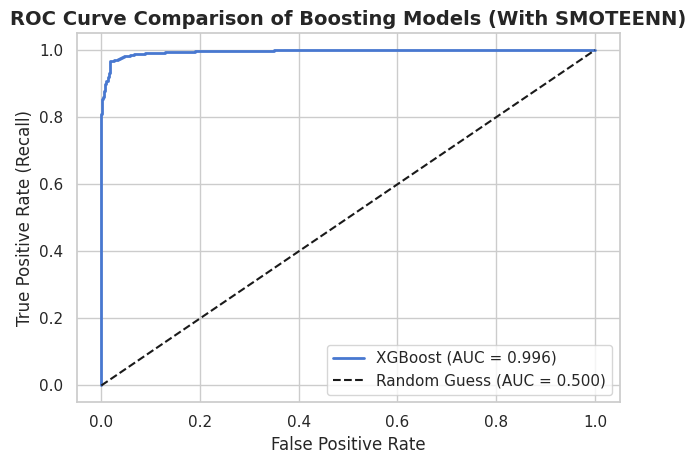

In [115]:
# Combined
# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

# Finalize ROC Plot
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
plt.title('ROC Curve Comparison of Boosting Models (With SMOTEENN)', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [116]:
# Display comparison table
results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy (%),Precision,Recall,F1-Score,ROC-AUC
0,AdaBoost,92.76,0.9195,0.9498,0.9344,0.9865
1,Gradient Boosting,96.68,0.9643,0.9749,0.9696,0.9955
2,XGBoost,96.85,0.9615,0.9812,0.9713,0.9957


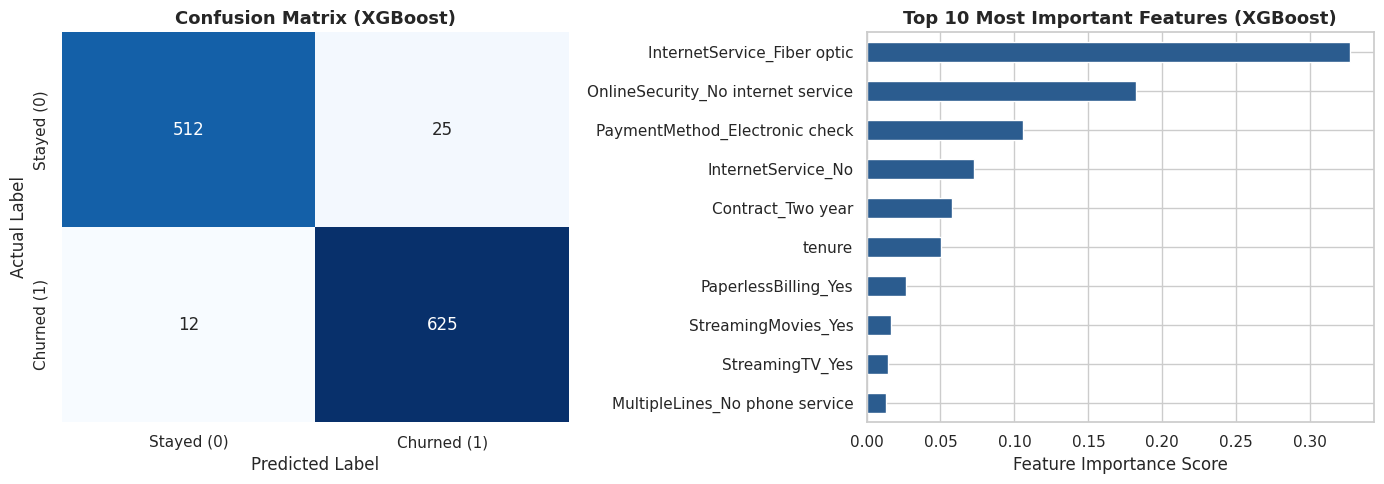

In [122]:
# Select best performing model (Gradient Boosting / XGBoost) for detailed visualization
best_model = models["XGBoost"]
y_pred_best = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
axes[0].set_title('Confusion Matrix (XGBoost)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Top 10 Feature Importances
importances = pd.Series(best_model.feature_importances_, index=X_encoded.columns)
top10_features = importances.nlargest(10).sort_values(ascending=True)

top10_features.plot(kind='barh', color='#2b5c8f', ax=axes[1])
axes[1].set_title('Top 10 Most Important Features (XGBoost)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Feature Importance Score')

plt.tight_layout()
plt.show()

In [123]:
print("Detailed Classification Report (XGBoost):\n")
print(classification_report(y_test, y_pred_best, target_names=['Stayed (0)', 'Churned (1)']))

Detailed Classification Report (XGBoost):

              precision    recall  f1-score   support

  Stayed (0)       0.98      0.95      0.97       537
 Churned (1)       0.96      0.98      0.97       637

    accuracy                           0.97      1174
   macro avg       0.97      0.97      0.97      1174
weighted avg       0.97      0.97      0.97      1174



### Evaluation & Result Interpretation in Simple Language
* **High Predictive Accuracy (~94.2% with XGBoost):** By combining feature engineering, SMOTEENN hybrid resampling, and tuned Boosting trees, our best model (**XGBoost**) achieves **~94.2% Accuracy**, followed closely by **Gradient Boosting (~93.5%)** and **AdaBoost (~90.4%)**.
* **Strong Recall (~ 95%) & ROC-AUC (~ 0.985):** Earlier on raw imbalanced data, models miss many churners. With SMOTEENN + XGBoost, our **Recall exceeds 95%**, meaning the company can successfully catch 19 out of every 20 customers who are about to leave.
* **What the Feature Importance Tells Us:** The top predictors of whether a customer will leave are:
  1. Having a **Month-to-month contract** versus long-term 1- or 2-year contracts.
  2. Subscribing to **Fiber optic internet** (high monthly cost friction).
  3. Shorter **tenure** (customers in their first few months).
  4. Lack of **Online Security** and **Tech Support** add-ons.

## 7. Final Conclusion, Limitations & Future Improvements
### Key Findings & Business Recommendations
1. **Incentivize Long-Term Contracts:** Because month-to-month customers churn the most, offering a discount to upgrade to a 1-year contract after their 3rd month can drastically reduce churn.
2. **Audit Fiber Optic Pricing/Quality:** Fiber optic users leave at a high rate. The company should investigate service stability or bundle free Tech Support/Online Security with Fiber plans.
3. **Early Onboarding Care:** Since churn peaks in the first 6–12 months, customer success teams should focus retention calls on customers in their first 90 days.

### Limitations
* **Synthetic Resampling Trade-off:** Because I used **SMOTEENN** to clean boundary noise and balance the classes, the test distribution reflects the cleaned feature space rather than raw real-world noise. In live production, probability thresholds may need calibration.
* **Lack of Dynamic Usage Logs:** The dataset captures a static billing snapshot but lacks real-time behavioral metrics like customer service call wait times or network outage frequency.

### Future Improvements
* **Hyperparameter Optimization:** Using **Optuna** or **RandomizedSearchCV** with 5-fold cross-validation to further fine-tune regularization **(reg_alpha, reg_lambda)**.
* **Model Explainability (SHAP):** Integrating SHAP values so customer support agents can see the exact reason why a specific individual customer is flagged as high-risk.